# Chapitre 3 - Cours 4 : Index secondaires, multidimensionnels, plein texte et en mémoire

Ce notebook couvre la section *Other Indexing Structures* : les index secondaires, le
rangement des valeurs dans l'index (*Storing values within the index* : index groupé,
fichier de tas, index couvrant), les index multicolonnes (*Multi-column indexes*), la
recherche plein texte et floue (*Full-text search and fuzzy indexes*) et les bases en
mémoire (*Keeping everything in memory*). Les expériences utilisent nos propres
structures et la bibliothèque standard `sqlite3`.

**Plan.**

1. Les index secondaires : des clés non uniques.
2. Où ranger les données : fichier de tas, index groupé, index couvrant.
3. Les index multicolonnes : index concaténé et index multidimensionnel.
4. La recherche plein texte : index inversé, intersection, recherche floue.
5. Tout garder en mémoire.

In [1]:
import random
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Les index secondaires (section *Other Indexing Structures*)

Jusqu'ici, nos index étaient des index **clé-valeur**, comme une clé primaire : la clé
identifie un enregistrement unique (une ligne, un document, un sommet), et les autres
enregistrements s'y réfèrent par cette clé. Il est très courant d'ajouter des **index
secondaires** (`CREATE INDEX` en SQL) pour chercher par d'autres colonnes, par exemple
toutes les commandes d'un client par `user_id`.

**La différence : les valeurs indexées ne sont pas uniques.** Deux façons de s'en
accommoder :

1. chaque entrée de l'index contient la **liste** des identifiants de lignes qui
   correspondent (comme la *postings list* d'un index plein texte, section 4) ;
2. on rend chaque entrée **unique** en lui ajoutant l'identifiant de ligne :
   la clé de l'index devient `(user_id, id_ligne)`. Toutes les lignes d'un même client
   sont alors **voisines** dans l'ordre de l'index : une requête devient un parcours
   d'intervalle.

B-trees et arbres LSM conviennent tous deux. Implémentons la deuxième méthode avec
notre arbre B+.

In [2]:
rng = np.random.default_rng(0)
N = 50_000
commandes = pd.DataFrame({"id": np.arange(N), "user_id": S.zipf_keys(N, 5_000, s=0.8, seed=3),
                          "montant": np.round(rng.lognormal(3, 0.8, N), 2)})
primaire = S.BPlusTree(max_keys=64)
secondaire = S.BPlusTree(max_keys=64)
for row in commandes.itertuples(index=False):
    primaire.insert(int(row.id), (int(row.user_id), float(row.montant)))
    secondaire.insert((int(row.user_id), int(row.id)), None)  # clé unique : (user_id, id)

client = int(commandes.user_id.value_counts().index[0])
secondaire.page_reads = primaire.page_reads = 0
ids = [i for (u, i), _ in secondaire.range((client, -1), (client, N))]
lignes = [primaire.get(i) for i in ids]
print(f"client {client} : {len(ids)} commandes trouvées ;",
      f"pages lues dans l'index secondaire : {secondaire.page_reads},",
      f"dans l'index primaire : {primaire.page_reads} ({primaire.height} par commande)")

client 801 : 2244 commandes trouvées ; pages lues dans l'index secondaire : 73, dans l'index primaire : 6732 (3 par commande)


L'index secondaire trouve les identifiants en un seul parcours d'intervalle (quelques
pages) ; il faut ensuite aller chercher **chaque ligne** via l'index primaire, ce qui
coûte une descente complète par ligne. D'où la question de la section suivante : où
ranger les données elles-mêmes ?

> **À retenir.** Un index secondaire indexe une colonne non unique ; on le construit
> comme un index clé-valeur, soit avec des listes d'identifiants, soit en ajoutant
> l'identifiant à la clé. Chaque correspondance renvoie à la ligne complète, ailleurs.

## 2. Où ranger les données (section *Storing values within the index*)

La **clé** d'un index est ce que l'on cherche ; la **valeur** associée peut être :

- **la ligne elle-même** : c'est un **index groupé** (*clustered index*). La clé
  primaire d'une table InnoDB (MySQL) est toujours groupée ; SQL Server permet un index
  groupé par table ;
- **une référence** vers la ligne : soit sa clé primaire (ce que font les index
  secondaires d'InnoDB), soit son emplacement physique dans un **fichier de tas** (*heap
  file*), où les lignes sont rangées sans ordre particulier (PostgreSQL). Le tas évite de
  dupliquer les données quand il y a plusieurs index secondaires ;
- **un compromis** : un **index couvrant** (*covering index*, ou index avec colonnes
  incluses) stocke quelques colonnes en plus de la clé. Une requête qui n'a besoin que
  de ces colonnes est servie par l'index seul : on dit que l'index **couvre** la
  requête. Plus rapide en lecture, mais plus d'espace et des écritures plus lentes.

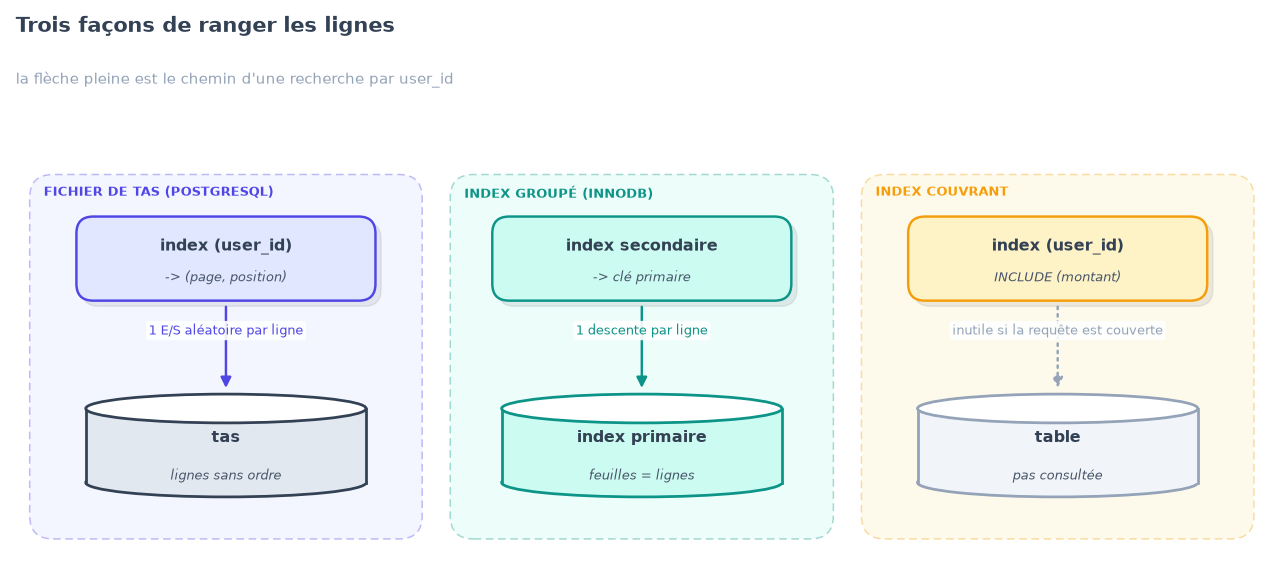

In [3]:
d = Diagram(13.5, 5.0, title="Trois façons de ranger les lignes",
            subtitle="la flèche pleine est le chemin d'une recherche par user_id")
d.group(0.2, 0.3, 4.4, 4.2, "fichier de tas (PostgreSQL)", color=INDIGO)
d.box("i1", 2.3, 3.3, "index (user_id)", sub="-> (page, position)", color=INDIGO, w=3.2)
d.box("h1", 2.3, 1.3, "tas", sub="lignes sans ordre", color=SLATE, kind="db", w=3.0, h=1.1)
d.arrow("i1", "h1", "1 E/S aléatoire par ligne", color=INDIGO)
d.group(4.7, 0.3, 8.8, 4.2, "index groupé (InnoDB)", color=TEAL)
d.box("i2", 6.75, 3.3, "index secondaire", sub="-> clé primaire", color=TEAL, w=3.2)
d.box("h2", 6.75, 1.3, "index primaire", sub="feuilles = lignes", color=TEAL, kind="db", w=3.0, h=1.1)
d.arrow("i2", "h2", "1 descente par ligne", color=TEAL)
d.group(9.1, 0.3, 13.3, 4.2, "index couvrant", color=AMBER)
d.box("i3", 11.2, 3.3, "index (user_id)", sub="INCLUDE (montant)", color=AMBER, w=3.2)
d.box("h3", 11.2, 1.3, "table", sub="pas consultée", color=GRAY, kind="db", w=3.0, h=1.1)
d.arrow("i3", "h3", "inutile si la requête est couverte", color=GRAY, style="dotted")
d.show()

**Quand l'index vaut-il mieux qu'un parcours complet ?** Modélisons une table d'un
million de lignes (50 lignes par page de tas, soit 20 000 pages) et une requête qui
sélectionne une fraction $s$ des lignes. Un parcours complet lit les 20 000 pages **en
séquence**. L'index secondaire lit quelques pages d'index puis, pour chaque ligne, une
page de tas **au hasard** : le nombre attendu de pages distinctes touchées par $m$
lignes vaut $P\,(1 - (1 - 1/P)^m)$. Un index groupé ou couvrant ne lit que les pages
contiguës qui contiennent les lignes voulues. On pondère une lecture séquentielle à 0,1
lecture aléatoire (ordre de grandeur sur SSD ; sur disque magnétique l'écart est bien
plus grand).

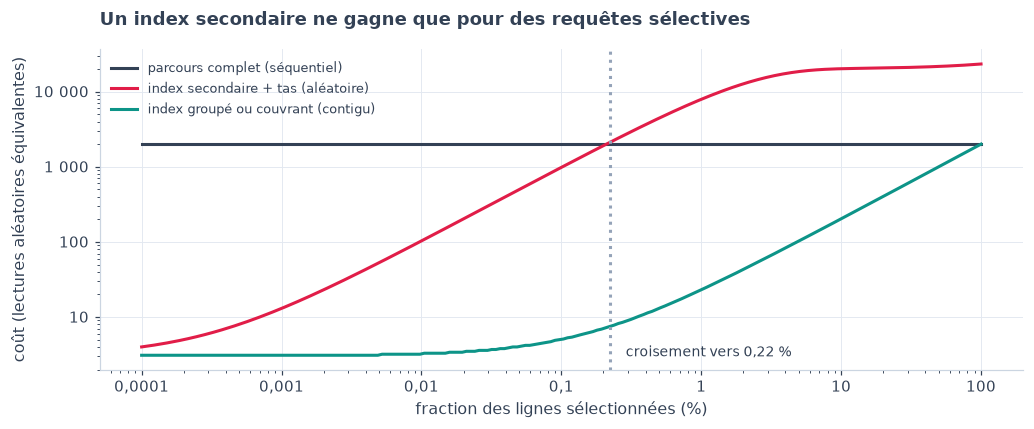

In [4]:
P, R, LEAF = 20_000, 50, 300
NR = P * R
s = np.logspace(-6, 0, 200)
m = s * NR
seq = 0.1
cout_scan = np.full_like(s, P * seq)
cout_tas = 3 + m / LEAF + P * (1 - (1 - 1 / P) ** m)
cout_groupe = 3 + np.ceil(m / R) * seq
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(s * 100, cout_scan, color=SLATE, label="parcours complet (séquentiel)")
ax.plot(s * 100, cout_tas, color=ROSE, label="index secondaire + tas (aléatoire)")
ax.plot(s * 100, cout_groupe, color=TEAL, label="index groupé ou couvrant (contigu)")
croise = s[np.argmax(cout_tas > cout_scan)] * 100
ax.axvline(croise, color=GRAY, ls=":")
ax.text(croise * 1.3, 3, f"croisement vers {croise:.2f} %".replace(".", ","), color=SLATE, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); S.plain_log_ticks(ax, "both")
ax.set_xlabel("fraction des lignes sélectionnées (%)"); ax.set_ylabel("coût (lectures aléatoires équivalentes)")
ax.set_title("Un index secondaire ne gagne que pour des requêtes sélectives")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec ce modèle, l'index secondaire sur un tas ne bat le parcours complet que si la
requête sélectionne **moins de quelques dixièmes de pourcent** des lignes. C'est
exactement le raisonnement de l'optimiseur de requêtes d'une base relationnelle, qui
préfère souvent un parcours séquentiel pour une requête peu sélective. L'index groupé
ou couvrant reste avantageux bien plus longtemps, car il lit des pages contiguës.

**Vérifions avec SQLite**, qui affiche son plan avec `EXPLAIN QUERY PLAN`. Une table
SQLite ordinaire est groupée sur un `rowid` caché ; on compare un index simple et un
index qui couvre la requête.

In [5]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE commandes (id INTEGER PRIMARY KEY, user_id INT, montant REAL, adresse TEXT)")
con.executemany("INSERT INTO commandes VALUES (?, ?, ?, ?)",
                [(int(r.id), int(r.user_id), float(r.montant), "x" * 200) for r in commandes.itertuples(index=False)])
requete = f"SELECT SUM(montant) FROM commandes WHERE user_id = {client}"


def plan(sql):
    return " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql))


def chrono(sql, rep=200):
    t0 = time.perf_counter()
    for _ in range(rep):
        con.execute(sql).fetchall()
    return (time.perf_counter() - t0) / rep * 1e6


lignes = [dict(configuration="aucun index", plan=plan(requete), us_par_requete=chrono(requete, 20))]
con.execute("CREATE INDEX idx_user ON commandes(user_id)")
lignes.append(dict(configuration="index sur user_id", plan=plan(requete), us_par_requete=chrono(requete)))
con.execute("CREATE INDEX idx_user_couvrant ON commandes(user_id, montant)")
lignes.append(dict(configuration="index couvrant (user_id, montant)", plan=plan(requete),
                   us_par_requete=chrono(requete)))
pd.DataFrame(lignes)

,configuration,plan,us_par_requete
0,aucun index,SCAN commandes,941.920
1,index sur user_id,SEARCH commandes USING INDEX idx_user (user_id=?),320.074
2,"index couvrant (user_id, montant)",SEARCH commandes USING COVERING INDEX idx_user...,58.331


Sans index : `SCAN` (parcours complet). Avec l'index sur `user_id` : `SEARCH ... USING
INDEX`, puis une visite de la table par ligne trouvée. Avec l'index couvrant : `USING
COVERING INDEX`, la table n'est plus consultée et la requête est encore plus rapide.
(Les temps dépendent de la machine ; l'ordre de grandeur et le classement, eux, sont
stables.)

**Mises à jour dans un tas.** Si une ligne mise à jour ne grossit pas, on peut
l'écraser en place. Si elle grossit, il faut la déplacer : soit on met à jour **tous**
les index qui pointaient vers l'ancien emplacement, soit on laisse un **pointeur de
réacheminement** à l'ancienne place.

> **À retenir.** La valeur d'un index est soit la ligne (index groupé), soit une
> référence (clé primaire ou emplacement dans un tas), soit quelques colonnes (index
> couvrant). Les index secondaires sur tas ne paient que pour les requêtes sélectives.

## 3. Les index multicolonnes (section *Multi-column indexes*)

**Index concaténé.** Le plus courant combine plusieurs champs en une seule clé, en les
mettant bout à bout dans un ordre fixé : comme un annuaire papier trié par
`(nom, prénom)`. Il sert pour un nom, ou un couple (nom, prénom), mais **pas** pour un
prénom seul.

**Index multidimensionnel.** Une carte de restaurants doit trouver tous les points d'un
rectangle :

```sql
SELECT * FROM restaurants WHERE lat BETWEEN 48.85 AND 48.87 AND lon BETWEEN 2.33 AND 2.36;
```

Un index concaténé `(lat, lon)` donne tous les restaurants d'une **bande** de latitudes
(à toutes les longitudes) ; il faut ensuite filtrer. Options : traduire le point 2D en
un seul nombre par une **courbe qui remplit l'espace** (par exemple la courbe de Morton,
ou ordre Z, qui entrelace les bits des deux coordonnées) puis utiliser un B-tree
ordinaire ; ou, plus couramment, un index **spatial** comme le **R-tree**, qui regroupe
les points proches dans le même sous-arbre. On peut aussi découper l'espace en grille.

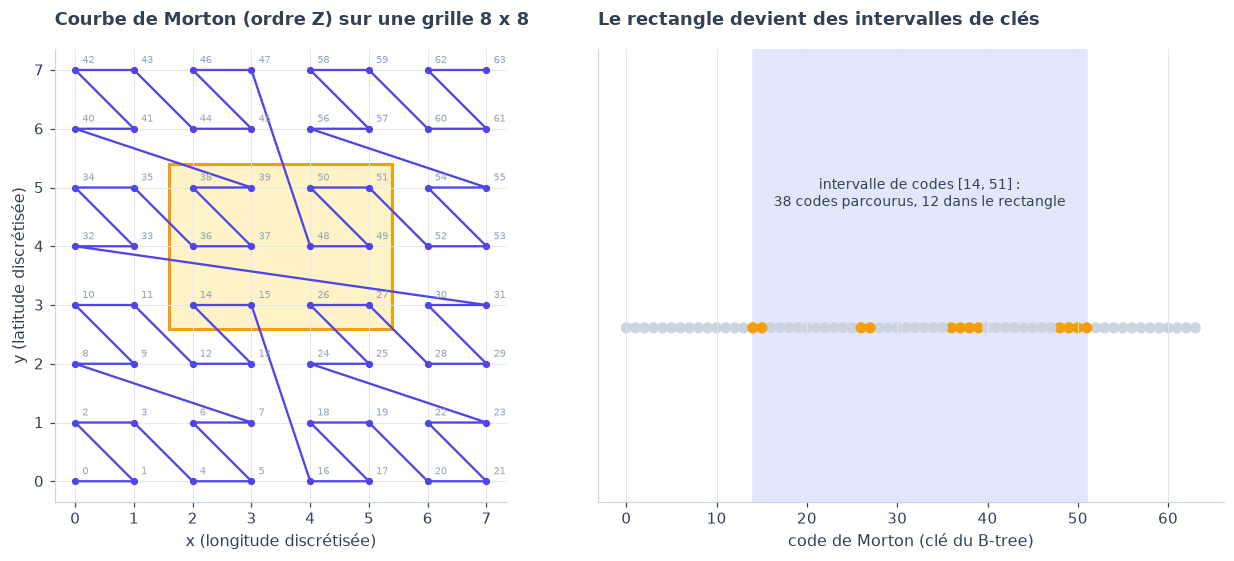

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ax = axes[0]
g = 8
xs, ys = np.meshgrid(np.arange(g), np.arange(g))
z = S.zorder(xs.ravel(), ys.ravel())
ordre = np.argsort(z)
ax.plot(xs.ravel()[ordre], ys.ravel()[ordre], "-", color=INDIGO, lw=1.5)
ax.scatter(xs.ravel(), ys.ravel(), s=14, color=INDIGO, zorder=3)
for xi, yi, zi in zip(xs.ravel(), ys.ravel(), z):
    ax.text(xi + 0.12, yi + 0.12, str(int(zi)), fontsize=6.5, color=GRAY)
ax.add_patch(plt.Rectangle((1.6, 2.6), 3.8, 2.8, facecolor=LIGHT[AMBER], edgecolor=AMBER, lw=2, zorder=0))
ax.set_aspect("equal"); ax.set_xticks(range(g)); ax.set_yticks(range(g))
ax.set_xlabel("x (longitude discrétisée)"); ax.set_ylabel("y (latitude discrétisée)")
ax.set_title("Courbe de Morton (ordre Z) sur une grille 8 x 8")
ax = axes[1]
zz = S.zorder(xs.ravel(), ys.ravel())
dans = (xs.ravel() >= 2) & (xs.ravel() <= 5) & (ys.ravel() >= 3) & (ys.ravel() <= 5)
ax.scatter(zz, np.zeros_like(zz), c=np.where(dans, AMBER, "#CBD5E1"), s=40)
zmin, zmax = zz[dans].min(), zz[dans].max()
ax.axvspan(zmin, zmax, color=LIGHT[INDIGO], zorder=0)
ax.text((zmin + zmax) / 2, 0.035, f"intervalle de codes [{zmin}, {zmax}] :\n{zmax - zmin + 1} codes parcourus, "
        f"{dans.sum()} dans le rectangle", ha="center", fontsize=9, color=SLATE)
ax.set_yticks([]); ax.set_ylim(-0.05, 0.08)
ax.set_xlabel("code de Morton (clé du B-tree)")
ax.set_title("Le rectangle devient des intervalles de clés")
finish(fig)
plt.show()

Les points d'un même petit carré ont des codes voisins ; un rectangle se traduit en un
ou quelques intervalles de codes. Un seul intervalle `[zmin, zmax]` contient des points
hors du rectangle (les « sauts » de la courbe) : les vrais moteurs le découpent en
plusieurs sous-intervalles. Mesurons le nombre de lignes examinées pour 100 000
restaurants autour de Paris et une fenêtre de carte.

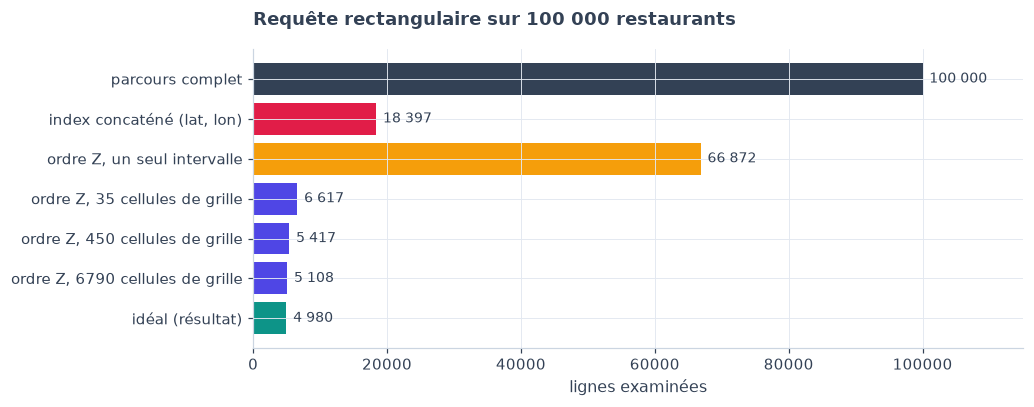

In [7]:
rng = np.random.default_rng(1)
n_r = 100_000
centres = np.array([[48.857, 2.352], [48.87, 2.30], [48.83, 2.38], [48.89, 2.34]])
c = centres[rng.integers(0, len(centres), n_r)]
lat = c[:, 0] + rng.normal(0, 0.02, n_r)
lon = c[:, 1] + rng.normal(0, 0.03, n_r)
rect = dict(lat=(48.85, 48.865), lon=(2.33, 2.36))
dans = (lat >= rect["lat"][0]) & (lat <= rect["lat"][1]) & (lon >= rect["lon"][0]) & (lon <= rect["lon"][1])


def discret(v, lo, hi, bits=16):
    return np.clip(((v - lo) / (hi - lo) * (2**bits - 1)).astype(np.int64), 0, 2**bits - 1)


LAT0, LAT1, LON0, LON1 = lat.min(), lat.max(), lon.min(), lon.max()
zc = S.zorder(discret(lon, LON0, LON1), discret(lat, LAT0, LAT1))
z_lo = S.zorder(discret(np.array([rect["lon"][0]]), LON0, LON1), discret(np.array([rect["lat"][0]]), LAT0, LAT1))[0]
z_hi = S.zorder(discret(np.array([rect["lon"][1]]), LON0, LON1), discret(np.array([rect["lat"][1]]), LAT0, LAT1))[0]


def z_sous_intervalles(niveau):
    """Découpe le rectangle en cellules de la grille 2^niveau et renvoie le nombre de lignes
    examinées en parcourant l'intervalle de codes de chaque cellule touchée."""
    shift = 16 - niveau
    gx = discret(lon, LON0, LON1) >> shift
    gy = discret(lat, LAT0, LAT1) >> shift
    x0, x1 = discret(np.array(rect["lon"]), LON0, LON1) >> shift
    y0, y1 = discret(np.array(rect["lat"]), LAT0, LAT1) >> shift
    cell = (gx >= x0) & (gx <= x1) & (gy >= y0) & (gy <= y1)
    return int(cell.sum()), int((x1 - x0 + 1) * (y1 - y0 + 1))


examines = {
    "parcours complet": n_r,
    "index concaténé (lat, lon)": int(((lat >= rect["lat"][0]) & (lat <= rect["lat"][1])).sum()),
    "ordre Z, un seul intervalle": int(((zc >= z_lo) & (zc <= z_hi)).sum()),
}
for niv in (6, 8, 10):
    lignes_, cellules = z_sous_intervalles(niv)
    examines[f"ordre Z, {cellules} cellules de grille"] = lignes_
examines["idéal (résultat)"] = int(dans.sum())
ex = pd.Series(examines, name="lignes examinées")
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.barh(range(len(ex)), ex.values, color=[SLATE, ROSE, AMBER, INDIGO, INDIGO, INDIGO, TEAL])
ax.set_yticks(range(len(ex)), ex.index); ax.invert_yaxis()
for y, v in enumerate(ex.values):
    ax.text(v + 1000, y, f"{v:,}".replace(",", " "), va="center", fontsize=9)
ax.set_xlim(right=n_r * 1.15)
ax.set_xlabel("lignes examinées")
ax.set_title("Requête rectangulaire sur 100 000 restaurants")
plt.tight_layout(); plt.show()

L'index concaténé examine toute une bande de latitudes (près de 20 000 lignes) pour en
garder environ 5 000. L'ordre Z avec **un seul** intervalle fait encore pire : notre
rectangle chevauche un « saut » de la courbe et l'intervalle `[zmin, zmax]` couvre les
deux tiers de la carte. Mais en découpant le rectangle en cellules de grille, dont
chacune correspond à un intervalle de codes contigu (des cellules voisines fusionnent
souvent en un même intervalle), on s'approche très vite du résultat exact. Les R-trees obtiennent un effet comparable en regroupant les points
voisins dans les mêmes pages.

Les index multidimensionnels ne servent pas qu'à la géographie : couleurs `(rouge, vert,
bleu)` d'un catalogue, ou `(date, température)` d'observations météo pour trouver les
journées entre 25 et 30 °C d'une année donnée sans parcourir toute l'année.

> **À retenir.** Un index concaténé ne sert que pour un **préfixe** de ses colonnes.
> Pour des intervalles sur plusieurs dimensions à la fois, il faut un index
> multidimensionnel : courbe qui remplit l'espace + B-tree, R-tree, ou grille.

## 4. La recherche plein texte (section *Full-text search and fuzzy indexes*)

**Le besoin.** Trouver les documents qui contiennent certains mots, n'importe où dans le
texte. La recherche d'information est un domaine à part entière (découpage en mots selon
la langue, formes grammaticales, synonymes, fautes de frappe) ; on s'en tient ici au
mécanisme d'indexation.

**L'index inversé.** On peut voir la recherche plein texte comme une requête
multidimensionnelle où chaque **terme** est une dimension (le document contient le terme
ou non). La structure utilisée est l'**index inversé** : une table clé-valeur dont la clé
est un terme et la valeur la liste triée des identifiants des documents qui le
contiennent, la **postings list**. Chercher deux mots, c'est **intersecter** deux listes
triées (ou faire le ET de deux bitmaps). Lucene, le moteur d'Elasticsearch et de Solr,
range ces listes dans des fichiers triés de type SSTable, fusionnés en tâche de fond
comme dans un LSM.

Construisons un index sur 20 000 documents synthétiques (vocabulaire de 5 000 mots, loi
de Zipf comme dans une vraie langue).

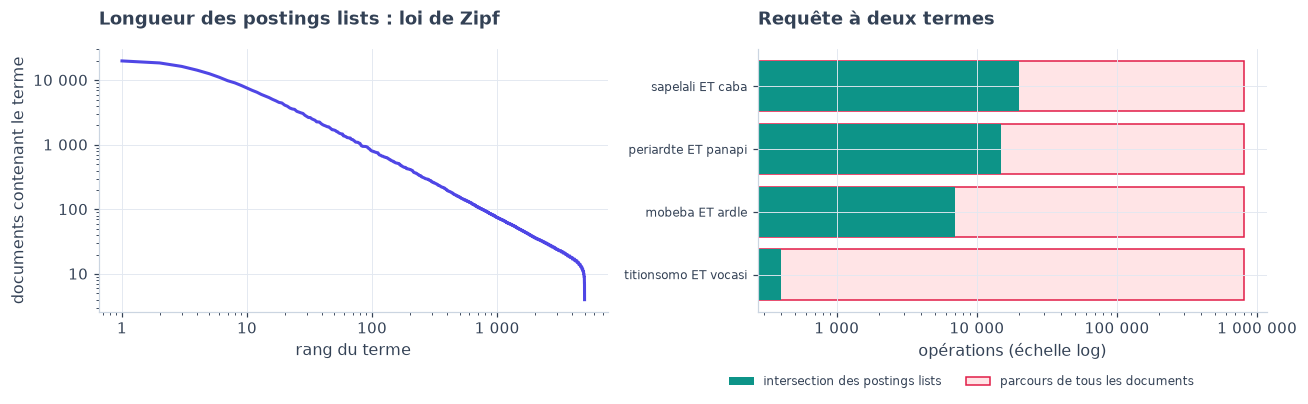

index construit en 0.22 s : 5000 termes, 612410 entrées


,requete,resultats,comparaisons,mots_lus_scan
0,sapelali ET caba,18471,19996,800000
1,periardte ET panapi,1421,14839,800000
2,mobeba ET ardle,23,7007,800000
3,titionsomo ET vocasi,0,400,800000


In [8]:
vocab = S.make_vocabulary(5_000, seed=0)
docs = S.make_documents(20_000, vocab, words_per_doc=40, s=1.05, seed=0)
t0 = time.perf_counter()
inv = S.InvertedIndex()
for i, d_ in enumerate(docs):
    inv.add(i, d_)
t_build = time.perf_counter() - t0
tailles = pd.Series({t: len(p) for t, p in inv.postings.items()}).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
ax.loglog(np.arange(1, len(tailles) + 1), tailles.values, color=INDIGO)
ax.set_xlabel("rang du terme"); ax.set_ylabel("documents contenant le terme")
S.plain_log_ticks(ax, "both")
ax.set_title("Longueur des postings lists : loi de Zipf")
ax = axes[1]
q_rows = []
for a, b in [(vocab[0], vocab[1]), (vocab[3], vocab[40]), (vocab[10], vocab[900]), (vocab[200], vocab[3000])]:
    res, comps = inv.search_and([a, b])
    t0 = time.perf_counter()
    brute = [i for i, d_ in enumerate(docs) if a in d_.split() and b in d_.split()]
    q_rows.append(dict(requete=f"{a} ET {b}", resultats=len(res), comparaisons=comps, mots_lus_scan=40 * len(docs)))
    assert brute == res
q = pd.DataFrame(q_rows)
ax.barh(range(len(q)), q.comparaisons, color=TEAL, label="intersection des postings lists")
ax.barh(range(len(q)), q.mots_lus_scan, color=LIGHT[ROSE], edgecolor=ROSE, label="parcours de tous les documents",
        zorder=0)
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.set_yticks(range(len(q)), q.requete, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("opérations (échelle log)"); ax.set_title("Requête à deux termes")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2)
finish(fig)
plt.show()
print(f"index construit en {t_build:.2f} s : {len(inv.postings)} termes, "
      f"{sum(len(p) for p in inv.postings.values())} entrées")
q

Quelques termes très fréquents ont des listes énormes, la plupart des termes des listes
courtes. L'intersection ne parcourt que les deux listes (et commence par la plus courte) :
selon les termes, de quelques centaines à une vingtaine de milliers de comparaisons,
contre 800 000 mots à lire pour un parcours naïf (et la liste la plus courte borne le
travail : deux termes rares coûtent presque rien). Quand les identifiants sont des entiers
consécutifs, une postings list peut aussi être un **bitmap** (un bit par document),
éventuellement compressé : le ET de deux bitmaps est extrêmement rapide (nous
retrouverons cette idée dans le stockage en colonnes, cours 5).

In [9]:
a, b = vocab[3], vocab[40]
bm = inv.bitmap(a) & inv.bitmap(b)
print(f"{a} : {inv.bitmap(a).sum()} documents ; {b} : {inv.bitmap(b).sum()} ; ET des bitmaps : {bm.sum()} documents",
      f"(identique à l'intersection : {np.flatnonzero(bm).tolist() == inv.search_and([a, b])[0]})")

periardte : 14302 documents ; panapi : 1979 ; ET des bitmaps : 1421 documents (identique à l'intersection : True)


**Recherche floue.** Pour tolérer les fautes de frappe, Lucene sait trouver les termes à
une **distance d'édition** donnée (une distance de 1 : une lettre ajoutée, supprimée ou
remplacée). La distance de Levenshtein se calcule par programmation dynamique : la case
$(i, j)$ contient la distance entre les $i$ premières lettres du premier mot et les $j$
premières du second.

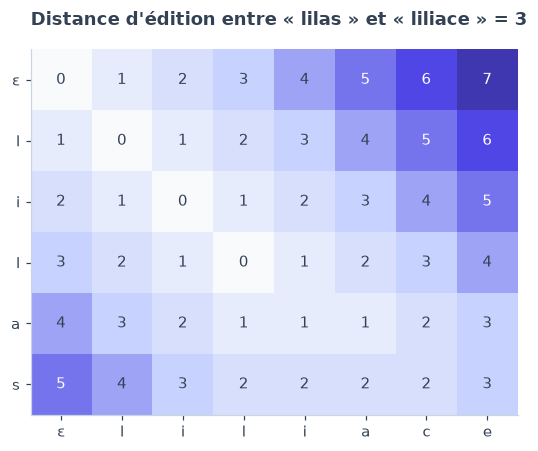

In [10]:
m1, m2 = "lilas", "liliace"
D = np.zeros((len(m1) + 1, len(m2) + 1), dtype=int)
D[:, 0] = np.arange(len(m1) + 1)
D[0, :] = np.arange(len(m2) + 1)
for i in range(1, len(m1) + 1):
    for j in range(1, len(m2) + 1):
        D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (m1[i - 1] != m2[j - 1]))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.imshow(D, cmap="ddia_seq", vmin=0, vmax=D.max() + 2)
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        ax.text(j, i, D[i, j], ha="center", va="center", fontsize=10,
                color="white" if D[i, j] > D.max() * 0.6 else SLATE)
ax.set_xticks(range(len(m2) + 1), ["ε"] + list(m2)); ax.set_yticks(range(len(m1) + 1), ["ε"] + list(m1))
ax.grid(False)
ax.set_title(f"Distance d'édition entre « {m1} » et « {m2} » = {D[-1, -1]}")
plt.tight_layout(); plt.show()

Calculer cette table pour **chaque** terme du vocabulaire serait coûteux. Lucene range
ses termes dans un automate à états finis proche d'un **trie** (arbre des préfixes) et le
combine avec un **automate de Levenshtein** pour n'explorer que les préfixes encore
compatibles. Notre `S.Trie.fuzzy` applique la même idée : une ligne de la table par nœud
du trie, et on abandonne une branche dès que toute la ligne dépasse la distance permise.

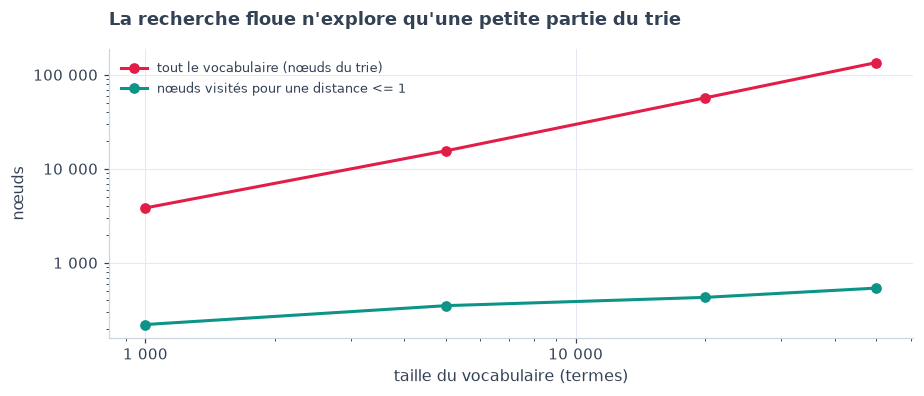

,vocabulaire,noeuds_du_trie,noeuds_visites,fraction_visitee
0,1000,3859,221.733,0.057
1,5000,15647,352.167,0.023
2,20000,57222,431.433,0.008
3,50000,135914,541.500,0.004


In [11]:
rows = []
for n_vocab in [1_000, 5_000, 20_000, 50_000]:
    v = S.make_vocabulary(n_vocab, seed=2)
    trie = S.Trie(v)
    rng_ = random.Random(0)
    visites = []
    for _ in range(30):
        w = rng_.choice(v)
        pos = rng_.randrange(len(w))
        faute = w[:pos] + "x" + w[pos + 1:]
        res, vis = trie.fuzzy(faute, 1)
        assert any(r == w for r, _ in res)
        visites.append(vis)
    rows.append(dict(vocabulaire=n_vocab, noeuds_du_trie=trie.n_nodes, noeuds_visites=np.mean(visites),
                     fraction_visitee=np.mean(visites) / trie.n_nodes))
fz = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.plot(fz.vocabulaire, fz.noeuds_du_trie, "o-", color=ROSE, label="tout le vocabulaire (nœuds du trie)")
ax.plot(fz.vocabulaire, fz.noeuds_visites, "o-", color=TEAL, label="nœuds visités pour une distance <= 1")
ax.set_xscale("log"); ax.set_yscale("log"); S.plain_log_ticks(ax, "both")
ax.set_xlabel("taille du vocabulaire (termes)"); ax.set_ylabel("nœuds")
ax.set_title("La recherche floue n'explore qu'une petite partie du trie")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
fz

La recherche floue retrouve toujours le mot d'origine (vérifié par `assert`) en visitant
une fraction du trie qui **diminue** quand le vocabulaire grandit : le nombre de nœuds
visités croît beaucoup moins vite que le vocabulaire.

> **À retenir.** Un index inversé associe à chaque terme la liste triée des documents
> qui le contiennent ; une requête à plusieurs termes est une intersection de listes (ou
> un ET de bitmaps). La recherche floue combine un trie (ou un automate) des termes et
> la distance d'édition calculée préfixe par préfixe.

## 5. Tout garder en mémoire (section *Keeping everything in memory*)

Toutes les structures vues jusqu'ici répondent aux contraintes des **disques** : il faut
disposer les données avec soin pour de bonnes performances. On tolère cette gêne car les
disques sont **durables** et **moins chers** au gigaoctet que la RAM. Mais la RAM baisse
de prix, et beaucoup de jeux de données ne sont pas si gros : on peut les garder
entièrement en mémoire, éventuellement répartis sur plusieurs machines. D'où les **bases
en mémoire** :

- certaines ne servent que de cache (Memcached) : perdre les données au redémarrage est
  acceptable ;
- d'autres visent la durabilité : matériel spécial (RAM sur batterie), ou plus souvent
  un **journal** des modifications sur disque, des **instantanés** périodiques, ou une
  **réplication** vers d'autres machines. Le disque ne sert alors qu'à la reprise, les
  lectures sont servies entièrement depuis la mémoire (VoltDB, MemSQL, RAMCloud ; Redis
  et Couchbase avec une durabilité faible, par écriture asynchrone).

**Contre-intuitif** : leur avantage ne vient pas de ce qu'elles évitent de lire le
disque. Un moteur sur disque n'y touche presque plus si la mémoire suffit, grâce au cache
du système. Elles sont rapides parce qu'elles évitent de **coder** leurs structures dans
un format écrivable sur disque. Mesurons ce coût : une recherche dans un dictionnaire
Python, dans notre B-tree (pages en mémoire, déjà décodées), et dans un B-tree dont la
page feuille doit être **décodée** (désérialisée) à chaque accès, comme une page lue
depuis le cache du système.

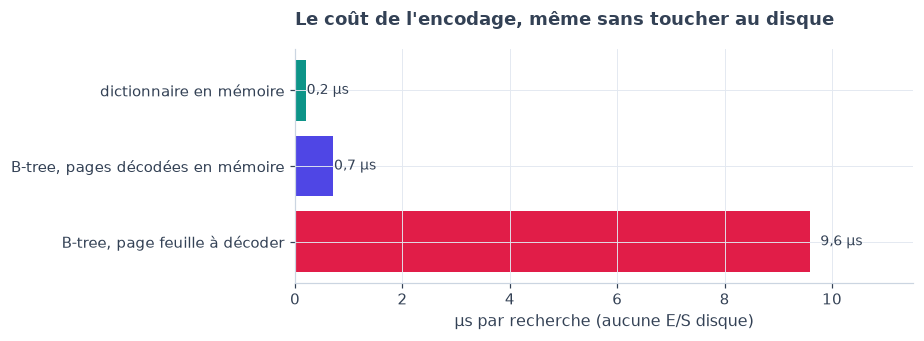

In [12]:
import pickle

n = 100_000
cles = [S.kv_key(i) for i in range(n)]
dico = {k: S.kv_value(i) for i, k in enumerate(cles)}
bt = S.BPlusTree(max_keys=64)
for k in cles:
    bt.insert(k, dico[k])
pages_codees = {pid: pickle.dumps(p) for pid, p in bt.pages.items() if p.leaf}


def get_avec_decodage(key):
    p = bt.pages[bt.root]
    while not p.leaf:
        p = bt.pages[p.children[np.searchsorted(p.keys, key, side="right")]]
    page = pickle.loads(pages_codees[p.id])  # décodage de la page
    i = page.keys.index(key)
    return page.values[i]


essais = random.Random(0).sample(cles, 3000)
mesures = {}
for nom, f in [("dictionnaire en mémoire", dico.get), ("B-tree, pages décodées en mémoire", bt.get),
               ("B-tree, page feuille à décoder", get_avec_decodage)]:
    t0 = time.perf_counter()
    for k in essais:
        assert f(k) == dico[k]
    mesures[nom] = (time.perf_counter() - t0) / len(essais) * 1e6
mem = pd.Series(mesures)
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh(range(len(mem)), mem.values, color=[TEAL, INDIGO, ROSE])
ax.set_yticks(range(len(mem)), mem.index); ax.invert_yaxis()
for y, v in enumerate(mem.values):
    ax.text(v * 1.02, y, f"{v:.1f} µs".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(right=mem.max() * 1.2)
ax.set_xlabel("µs par recherche (aucune E/S disque)")
ax.set_title("Le coût de l'encodage, même sans toucher au disque")
plt.tight_layout(); plt.show()

Sans aucune E/S, décoder la page à chaque accès multiplie le coût d'une recherche par un
facteur important par rapport à la même structure déjà en mémoire. C'est le surcoût
qu'évitent les bases en mémoire. Elles permettent aussi des **modèles de données**
difficiles à réaliser sur disque : Redis offre des files de priorité, des ensembles, des
listes... avec une implémentation comparativement simple.

> **À retenir.** Une base en mémoire reste durable grâce à un journal, des instantanés
> ou la réplication. Elle est rapide surtout parce qu'elle évite d'encoder ses
> structures pour le disque, et elle autorise des structures de données plus riches.